# Harmonized data interface

This notebook demonstrates how processed sensor products are registered on a shared visualization grid. Modalities are optional: a cube may contain TLS alone, any other subset, or no layers while it is being assembled.

The TLS example uses the real Ankasa PLY point cloud. Its vertices are retained as a native point-cloud `DataLayer` and aggregated to a regular voxel layer for the cube. The aggregation shown here is provisional notebook code until the TLS cube generator owns this operation.

In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import xarray as xr

from tomo_canopy.processors import TLSProcessor
from tomo_canopy.types import (
    DataCube,
    DataLayer,
    GeometryType,
    GridSpec,
    Modality,
)

## Load real TLS data and define its grid

The provider reads the binary PLY vertices through memory maps (`load=False`). This PLY also contains triangular faces, but the data interface below intentionally exposes its vertices as a point cloud. Confirm the CRS from the source metadata before combining it with other modalities; the example uses UTM zone 30N. The 1 m grid coordinates represent voxel centres.

In [17]:
TLS_CRS = "EPSG:32630"
TLS_VOXEL_SIZE = 1.0  # metres
tls_candidates = [
    Path("data/TLS/Ankasa/c01_r02_subsampled_1cm_trees_mesh.ply"),
    Path("../data/TLS/Ankasa/c01_r02_subsampled_1cm_trees_mesh.ply"),
]
TLS_PATH = next((path for path in tls_candidates if path.is_file()), tls_candidates[0])

tls_processor = TLSProcessor()
tls_mesh = tls_processor.open(TLS_PATH, crs=TLS_CRS, load=False)
tls_bounds = tls_processor.bounds(tls_mesh)

# Discard connectivity for this visualization while retaining every vertex.
tls_points = tls_mesh.drop_vars("face_vertices").rename({"vertex": "point"})
tls_points.attrs = {**tls_mesh.attrs, "geometry_type": "point_cloud"}
tls_point_layer = DataLayer(
    name="tls_points",
    data=tls_points,
    modality=Modality.TLS,
    geometry=GeometryType.POINT_CLOUD,
)

minimum = dict(zip(tls_bounds.axis.values, tls_bounds.minimum.values))
maximum = dict(zip(tls_bounds.axis.values, tls_bounds.maximum.values))
edges = {
    axis: np.arange(
        np.floor(minimum[axis] / TLS_VOXEL_SIZE) * TLS_VOXEL_SIZE,
        np.ceil(maximum[axis] / TLS_VOXEL_SIZE) * TLS_VOXEL_SIZE
        + TLS_VOXEL_SIZE,
        TLS_VOXEL_SIZE,
    )
    for axis in ("x", "y", "z")
}
centres = {
    axis: (axis_edges[:-1] + axis_edges[1:]) / 2
    for axis, axis_edges in edges.items()
}
grid = GridSpec(
    x=centres["x"], y=centres["y"], z=centres["z"], crs=TLS_CRS
)
print(f"Native TLS points: {tls_points.sizes['point']:,}")
print("Grid shape (z, y, x):", grid.shape)

Native TLS points: 6,930,014
Grid shape (z, y, x): (44, 44, 71)


## Start without any modalities

An empty cube is valid. This allows an assembly workflow to add whichever products are available.

In [18]:
cube = DataCube(grid=grid)
expected = {Modality.TLS, Modality.ALS, Modality.GEDI, Modality.TOMOGRAM}
print("Present:", sorted(cube.modalities))
print("Missing:", sorted(cube.missing_modalities(expected)))

Present: []
Missing: ['als', 'gedi', 'tls', 'tomogram']


## Add the real TLS volume

The native `tls_point_layer` remains available for point-cloud rendering and processing. `DataCube` requires rectilinear coordinates, so all real TLS vertices are counted into the 1 m grid. Both point count and binary occupancy are retained.

In [19]:
point_count, _ = np.histogramdd(
    (tls_points.z.values, tls_points.y.values, tls_points.x.values),
    bins=(edges["z"], edges["y"], edges["x"]),
)
tls_dataset = xr.Dataset(
    {
        "point_count": (
            ("z", "y", "x"), point_count.astype(np.int32)
        ),
        "occupancy": (
            ("z", "y", "x"), point_count > 0
        ),
    },
    coords=grid.coordinates,
    attrs={
        "crs": grid.crs,
        "source": str(TLS_PATH.resolve()),
        "voxel_size": TLS_VOXEL_SIZE,
        "aggregation": "point count per voxel",
    },
)
tls_layer = DataLayer(
    name="tls_occupancy",
    data=tls_dataset,
    modality=Modality.TLS,
    geometry=GeometryType.VOLUME,
)
cube.add_layer(tls_point_layer, replace=True)
cube.add_layer(tls_layer, replace=True)

In [20]:
print("Has TLS:", cube.has_modality(Modality.TLS))
print("Has ALS:", cube.has_modality(Modality.ALS))
print("Still missing:", sorted(cube.missing_modalities(expected)))
print("TLS layers:", [layer.name for layer in cube.layers_for("tls")])

Has TLS: True
Has ALS: False
Still missing: ['als', 'gedi', 'tomogram']
TLS layers: ['tls_points', 'tls_occupancy']


## Visualize the available TLS product

Consumers render what is present rather than assuming every modality exists.

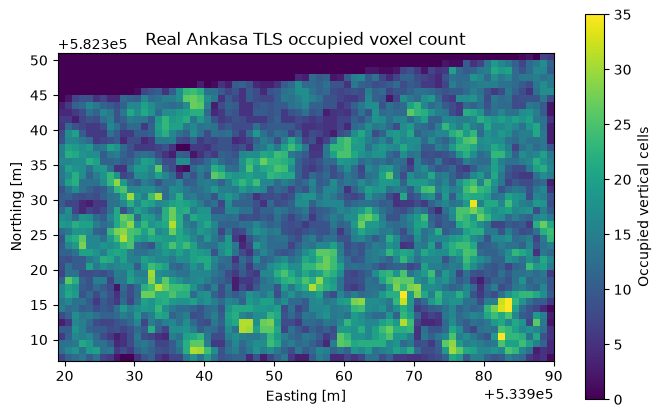

In [21]:
tls_height = tls_dataset.occupancy.sum("z")
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.pcolormesh(grid.x, grid.y, tls_height, shading="nearest")
ax.set_aspect("equal")
ax.set(
    xlabel="Easting [m]",
    ylabel="Northing [m]",
    title="Real Ankasa TLS occupied voxel count",
)
fig.colorbar(image, ax=ax, label="Occupied vertical cells")
plt.show()

### Render the TLS voxels in 3D

The preceding map is a 2D vertical summary. Here the same cube layer is rendered without collapsing `z`: every visible box is an occupied 1 m³ voxel, coloured by the logarithm of its TLS point count.

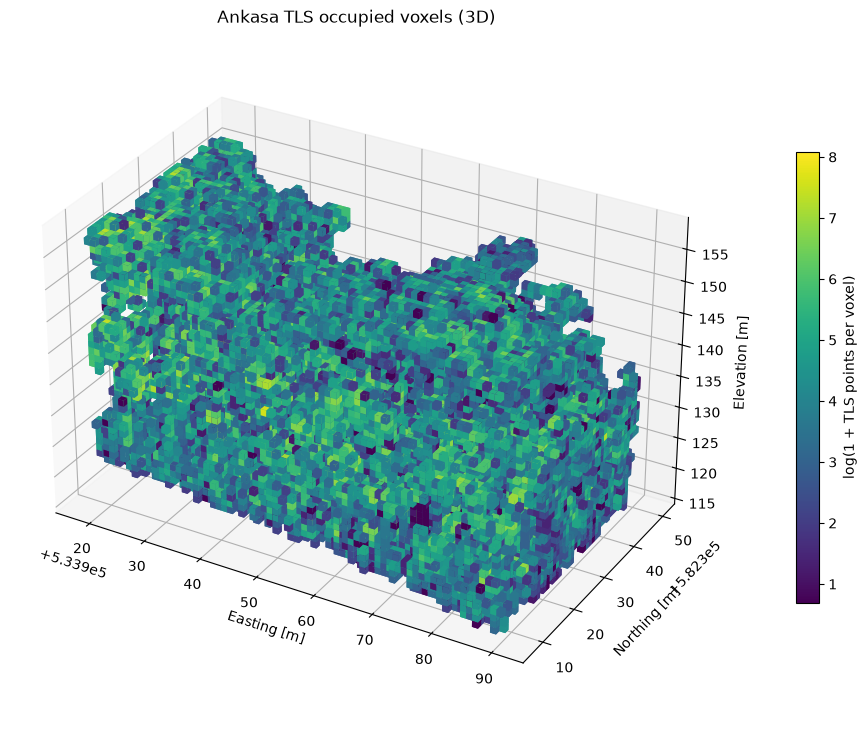

In [22]:
tls_volume = cube.layers["tls_occupancy"].data
voxel_counts = tls_volume.point_count.transpose("x", "y", "z").values
filled_voxels = voxel_counts > 0
log_counts = np.log1p(voxel_counts)
occupied_log_counts = log_counts[filled_voxels]
colour_norm = Normalize(
    vmin=float(occupied_log_counts.min()),
    vmax=float(occupied_log_counts.max()),
)
voxel_colours = plt.colormaps["viridis"](colour_norm(log_counts))
voxel_x, voxel_y, voxel_z = np.meshgrid(
    edges["x"], edges["y"], edges["z"], indexing="ij"
)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")
ax.voxels(
    voxel_x, voxel_y, voxel_z, filled_voxels,
    facecolors=voxel_colours, edgecolor=None, shade=False,
)
colour_scale = plt.cm.ScalarMappable(norm=colour_norm, cmap="viridis")
colour_scale.set_array([])
fig.colorbar(
    colour_scale, ax=ax, pad=0.1, shrink=0.65,
    label="log(1 + TLS points per voxel)",
)
ax.set(
    xlabel="Easting [m]", ylabel="Northing [m]",
    zlabel="Elevation [m]", title="Ankasa TLS occupied voxels (3D)",
)
ax.set_box_aspect((np.ptp(grid.x), np.ptp(grid.y), np.ptp(grid.z)))
plt.show()

## Optionally add ALS

A two-dimensional canopy-height layer may use the matching `x` and `y` subset of the three-dimensional grid. No GEDI or tomogram placeholder is needed.

In [23]:
xx, yy = np.meshgrid(grid.x, grid.y, indexing="xy")
x_scale = max(float(np.ptp(grid.x)), 1.0)
y_scale = max(float(np.ptp(grid.y)), 1.0)
canopy_height = 25.0 + 8.0 * np.exp(
    -(((xx - grid.x.mean()) / x_scale) ** 2
      + ((yy - grid.y.mean()) / y_scale) ** 2) * 8.0
)
als_dataset = xr.Dataset(
    {"canopy_height": (("y", "x"), canopy_height.astype("float32"))},
    coords={"x": grid.x, "y": grid.y},
    attrs={"crs": grid.crs},
)
cube.add_layer(
    DataLayer(
        name="als_canopy_height",
        data=als_dataset,
        modality=Modality.ALS,
        geometry=GeometryType.RASTER,
    )
)
print("Present after adding ALS:", sorted(cube.modalities))
print("Missing after adding ALS:", sorted(cube.missing_modalities(expected)))

Present after adding ALS: ['als', 'tls']
Missing after adding ALS: ['gedi', 'tomogram']


## Build the visualization dataset

`to_xarray()` combines only available layers. Variable names are prefixed with their layer names to avoid collisions.

In [24]:
visualization_data = cube.to_xarray()
visualization_data

<xarray.Dataset> Size: 195MB
Dimensions:                           (x: 71, y: 44, z: 44,
                                       tls_points__point: 6930014)
Coordinates:
  * x                                 (x) float64 568B 5.339e+05 ... 5.34e+05
  * y                                 (y) float64 352B 5.823e+05 ... 5.824e+05
  * z                                 (z) float64 352B 115.5 116.5 ... 158.5
    tls_points__x                     (tls_points__point) float64 55MB 5.339e...
    tls_points__y                     (tls_points__point) float64 55MB 5.823e...
    tls_points__z                     (tls_points__point) float64 55MB 123.5 ...
Dimensions without coordinates: tls_points__point
Data variables:
    tls_points__red                   (tls_points__point) uint8 7MB 192 ... 192
    tls_points__green                 (tls_points__point) uint8 7MB 166 ... 166
    tls_points__blue                  (tls_points__point) uint8 7MB 141 ... 141
    tls_points__alpha                 (tls_points__point) uint8 7MB 255 ... 255
    tls_occupancy__point_count        (z, y, x) int32 550kB 0 0 0 0 ... 0 0 0 0
    tls_occupancy__occupancy          (z, y, x) bool 137kB False False ... False
    als_canopy_height__canopy_height  (y, x) float32 12kB 25.15 25.16 ... 25.15
Attributes:
    crs:         EPSG:32630
    modalities:  ['als', 'tls']

## Require modalities only when necessary

Most visualization paths should adapt to available layers. An operation that specifically compares TLS against BIOMASS tomography can explicitly require both and provide a clear error otherwise.

In [25]:
try:
    cube.require_modalities(Modality.TLS, Modality.TOMOGRAM)
except ValueError as error:
    print(error)

Missing required modalities: tomogram


## Validation prevents accidental misalignment

A layer with shifted coordinates or another CRS is rejected before it reaches visualization. Reprojection and resampling belong in processors/transforms and cube generation.

In [26]:
shifted_dataset = xr.Dataset(
    {"value": (("y", "x"), np.ones((grid.y.size, grid.x.size)))},
    coords={"x": grid.x + 100.0, "y": grid.y},
    attrs={"crs": grid.crs},
)
shifted_layer = DataLayer(
    name="shifted_example",
    data=shifted_dataset,
    modality=Modality.OTHER,
    geometry=GeometryType.RASTER,
)
try:
    cube.add_layer(shifted_layer)
except ValueError as error:
    print(error)

Layer coordinate 'x' does not match the cube grid


## Add a real GEDI layer

This section queries GEDI observations from the public GFZ `gedidb` object store. The processor first exposes the native shots as a point-cloud `DataLayer`. Because `DataCube` accepts only layers aligned to a common rectilinear grid, the example then aggregates AGBD and RH98 into 1 km cells. This small aggregation is an example for exercising the interface; a reusable GEDI cube generator should eventually own that operation.

Install the optional dependencies before running this section: `python -m pip install -e '.[gedi,examples]'`. Internet access is required.

In [27]:
import geopandas as gpd
from shapely.geometry import box

from tomo_canopy.processors import GEDIProcessor

# Example area in southwest Ghana. Replace this box with the study site.
GEDI_BOUNDS = (-2.70, 5.10, -2.50, 5.30)
TARGET_CRS = "EPSG:32630"
roi = gpd.GeoDataFrame(
    geometry=[box(*GEDI_BOUNDS)],
    crs="EPSG:4326",
)

gedi_processor = GEDIProcessor()
gedi = gedi_processor.open(
    roi,
    variables=["agbd", "rh", "elev_lowestmode"],
    start_time="2019-01-01",
    end_time="2024-07-25",
)
print(f"Downloaded {gedi.sizes['shot_number']:,} GEDI shots")

Downloaded 21,234 GEDI shots


In [28]:
gedi_layer_native = None
gedi_projected = None

if gedi.sizes["shot_number"] == 0:
    print("No GEDI shots were found. Try a larger or different GEDI_BOUNDS.")
else:
    gedi_valid = gedi_processor.filter_valid(
        gedi, variables=["agbd", "rh", "elev_lowestmode"]
    )
    if gedi_valid.sizes["shot_number"] == 0:
        print("Shots were returned, but none contain both AGBD and RH data.")
    else:
        gedi_metrics = gedi_processor.add_rh_metric(
            gedi_valid, percentile=98, name="rh98"
        )
        gedi_projected = gedi_processor.reproject(
            gedi_metrics, target_crs=TARGET_CRS
        )
        gedi_layer_native = gedi_processor.to_data_layer(
            gedi_projected, name="gedi_shots"
        )
        print(gedi_layer_native)

DataLayer(name='gedi_shots', data=<xarray.Dataset> Size: 10MB
Dimensions:          (shot_number: 21234, profile_points: 101)
Coordinates:
  * shot_number      (shot_number) uint64 170kB 308180000300297325 ... 307800...
    latitude         (shot_number) float64 170kB 5.107 5.106 5.1 ... 5.11 5.109
    longitude        (shot_number) float64 170kB -2.679 -2.679 ... -2.514 -2.514
    time             (shot_number) datetime64[ns] 170kB 2024-05-22 ... 2019-0...
    x                (shot_number) float64 170kB 5.356e+05 ... 5.539e+05
    y                (shot_number) float64 170kB 5.645e+05 ... 5.648e+05
  * profile_points   (profile_points) int16 202B 0 1 2 3 4 5 ... 96 97 98 99 100
Data variables:
    elev_lowestmode  (shot_number) float32 85kB 82.41 80.99 59.51 ... 81.85 80.5
    agbd             (shot_number) float32 85kB 51.77 28.68 40.94 ... 126.2 73.8
    rh               (shot_number, profile_points) float32 9MB -3.31 ... 15.17
    rh98             (shot_number) float32 85kB 12.29 8

The geometry-aware cube accepts native GEDI shots directly, without forcing their irregular `shot_number` coordinates onto a grid. The next cell additionally creates a raster representation from the projected extent and calculates cell means plus shot counts.

In [29]:
gedi_cube = None
GEDI_CELL_SIZE = 1_000.0  # metres in EPSG:32630

if gedi_projected is not None:
    x_values = np.asarray(gedi_projected.x.values)
    y_values = np.asarray(gedi_projected.y.values)
    x_start = np.floor(x_values.min() / GEDI_CELL_SIZE) * GEDI_CELL_SIZE
    x_stop = np.ceil(x_values.max() / GEDI_CELL_SIZE) * GEDI_CELL_SIZE
    y_start = np.floor(y_values.min() / GEDI_CELL_SIZE) * GEDI_CELL_SIZE
    y_stop = np.ceil(y_values.max() / GEDI_CELL_SIZE) * GEDI_CELL_SIZE
    x_edges = np.arange(x_start, x_stop + GEDI_CELL_SIZE, GEDI_CELL_SIZE)
    y_edges = np.arange(y_start, y_stop + GEDI_CELL_SIZE, GEDI_CELL_SIZE)
    if x_edges.size < 2:
        x_edges = np.array([x_start, x_start + GEDI_CELL_SIZE])
    if y_edges.size < 2:
        y_edges = np.array([y_start, y_start + GEDI_CELL_SIZE])

    def cell_mean(values):
        values = np.asarray(values)
        valid = np.isfinite(values)
        totals, _, _ = np.histogram2d(
            y_values[valid], x_values[valid],
            bins=(y_edges, x_edges), weights=values[valid],
        )
        counts, _, _ = np.histogram2d(
            y_values[valid], x_values[valid], bins=(y_edges, x_edges)
        )
        return np.divide(
            totals, counts, out=np.full_like(totals, np.nan), where=counts > 0
        )

    shot_count, _, _ = np.histogram2d(
        y_values, x_values, bins=(y_edges, x_edges)
    )
    x_centres = (x_edges[:-1] + x_edges[1:]) / 2
    y_centres = (y_edges[:-1] + y_edges[1:]) / 2
    gedi_raster = xr.Dataset(
        data_vars={
            "agbd_mean": (("y", "x"), cell_mean(gedi_projected.agbd.values)),
            "rh98_mean": (("y", "x"), cell_mean(gedi_projected.rh98.values)),
            "shot_count": (("y", "x"), shot_count.astype(np.int64)),
        },
        coords={"x": x_centres, "y": y_centres},
        attrs={
            "crs": TARGET_CRS,
            "cell_size": GEDI_CELL_SIZE,
            "aggregation": "arithmetic mean per grid cell",
        },
    )
    gedi_grid = GridSpec(
        x=x_centres, y=y_centres, z=np.array([0.0]), crs=TARGET_CRS
    )
    gedi_raster_layer = DataLayer(
        name="gedi_metrics",
        data=gedi_raster,
        modality=Modality.GEDI,
        geometry=GeometryType.RASTER,
    )
    gedi_cube = DataCube(grid=gedi_grid)
    gedi_cube.add_layer(gedi_layer_native)
    gedi_cube.add_layer(gedi_raster_layer)
    display(gedi_cube.to_xarray())
    print("GEDI modality present:", gedi_cube.has_modality(Modality.GEDI))

<xarray.Dataset> Size: 10MB
Dimensions:                      (x: 23, y: 23, z: 1,
                                  gedi_shots__shot_number: 21234,
                                  gedi_shots__profile_points: 101)
Coordinates:
  * x                            (x) float64 184B 5.335e+05 ... 5.555e+05
  * y                            (y) float64 184B 5.635e+05 ... 5.855e+05
  * z                            (z) float64 8B 0.0
  * gedi_shots__shot_number      (gedi_shots__shot_number) uint64 170kB 30818...
    gedi_shots__latitude         (gedi_shots__shot_number) float64 170kB 5.10...
    gedi_shots__longitude        (gedi_shots__shot_number) float64 170kB -2.6...
    gedi_shots__time             (gedi_shots__shot_number) datetime64[ns] 170kB ...
    gedi_shots__x                (gedi_shots__shot_number) float64 170kB 5.35...
    gedi_shots__y                (gedi_shots__shot_number) float64 170kB 5.64...
  * gedi_shots__profile_points   (gedi_shots__profile_points) int16 202B 0 .....
Data variables:
    gedi_shots__elev_lowestmode  (gedi_shots__shot_number) float32 85kB 82.41...
    gedi_shots__agbd             (gedi_shots__shot_number) float32 85kB 51.77...
    gedi_shots__rh               (gedi_shots__shot_number, gedi_shots__profile_points) float32 9MB ...
    gedi_shots__rh98             (gedi_shots__shot_number) float32 85kB 12.29...
    gedi_metrics__agbd_mean      (y, x) float64 4kB 72.0 82.44 ... 158.0 122.6
    gedi_metrics__rh98_mean      (y, x) float64 4kB 15.65 15.16 ... 25.38 22.26
    gedi_metrics__shot_count     (y, x) int64 4kB 14 27 11 10 13 ... 68 37 85 28
Attributes:
    crs:         EPSG:32630
    modalities:  ['gedi']

GEDI modality present: True


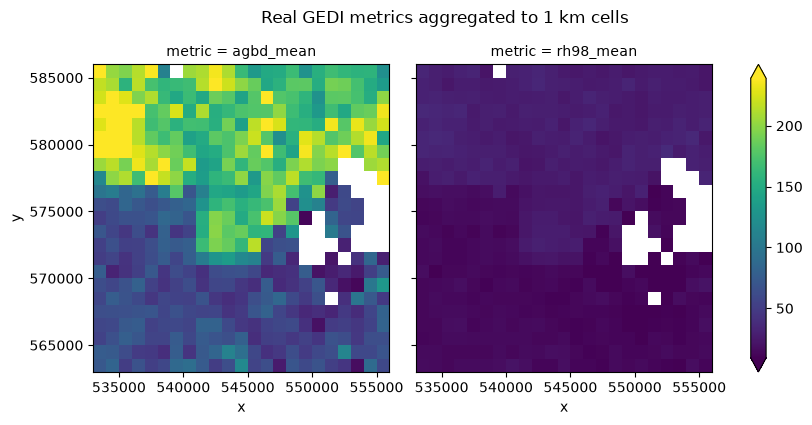

In [30]:
if gedi_cube is not None:
    axes = gedi_raster[["agbd_mean", "rh98_mean"]].to_array("metric").plot(
        col="metric", col_wrap=2, robust=True, size=4
    )
    axes.fig.suptitle("Real GEDI metrics aggregated to 1 km cells", y=1.05)

## Render native TLS and GEDI layers together in 3D

Both native layers use `EPSG:32630`, so GEDI shots can be spatially matched without voxelizing either dataset. The plot samples TLS only for rendering performance; the complete point cloud remains in the cube. Because a 70 × 43 m TLS plot may fall between sparse GEDI tracks, the view includes a labelled 250 m context around TLS and separately reports true footprint intersections. Each GEDI shot is drawn from `elev_lowestmode` to `elev_lowestmode + RH98`. Confirm that the TLS and GEDI vertical datums are compatible before interpreting absolute vertical agreement.

GEDI shots intersecting the TLS footprint: 0
GEDI shots in the 250 m context: 16


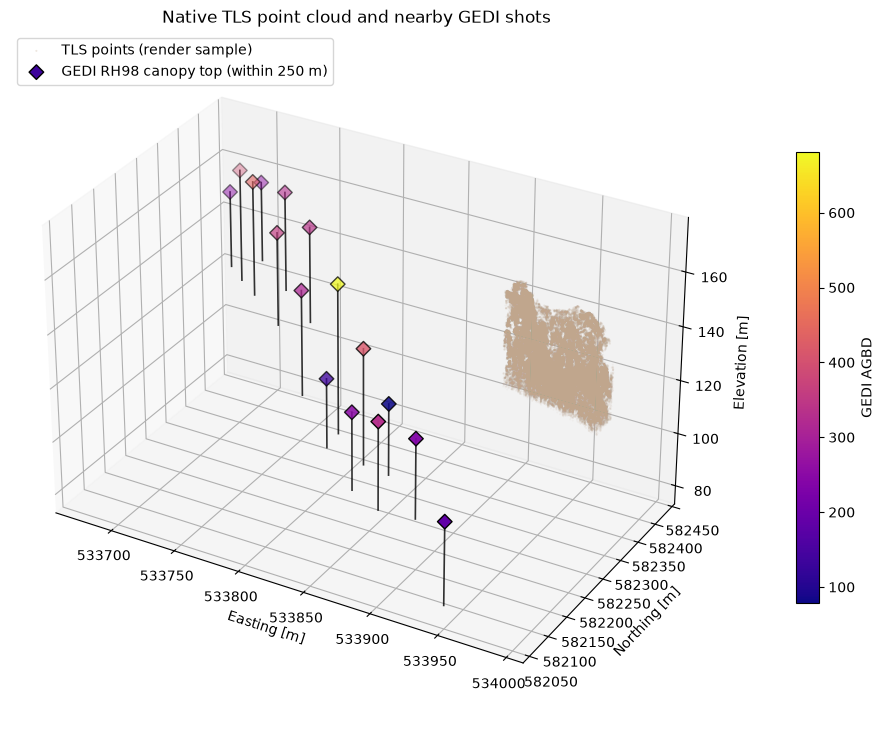

In [31]:
if gedi_layer_native is None:
    print("No valid GEDI layer is available for the 3D comparison.")
else:
    # Native layers share the cube CRS but retain their own dimensions.
    cube.add_layer(gedi_layer_native, replace=True)
    tls_3d = cube.layers["tls_points"].data
    gedi_3d = cube.layers["gedi_shots"].data

    inside_tls = (
        (gedi_3d.x >= edges["x"][0])
        & (gedi_3d.x < edges["x"][-1])
        & (gedi_3d.y >= edges["y"][0])
        & (gedi_3d.y < edges["y"][-1])
    )
    GEDI_CONTEXT_BUFFER = 250.0  # metres
    near_tls = (
        (gedi_3d.x >= edges["x"][0] - GEDI_CONTEXT_BUFFER)
        & (gedi_3d.x < edges["x"][-1] + GEDI_CONTEXT_BUFFER)
        & (gedi_3d.y >= edges["y"][0] - GEDI_CONTEXT_BUFFER)
        & (gedi_3d.y < edges["y"][-1] + GEDI_CONTEXT_BUFFER)
    )
    matched_gedi = gedi_3d.isel(
        shot_number=np.flatnonzero(near_tls.values)
    )
    print(f"GEDI shots intersecting the TLS footprint: {int(inside_tls.sum())}")
    print(f"GEDI shots in the 250 m context: {matched_gedi.sizes['shot_number']}")

    # Render a reproducible subset; the cube still holds all TLS points.
    render_count = min(150_000, tls_3d.sizes["point"])
    render_indices = np.random.default_rng(42).choice(
        tls_3d.sizes["point"], size=render_count, replace=False
    )
    tls_render = tls_3d.isel(point=render_indices)

    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(111, projection="3d")
    if {"red", "green", "blue"}.issubset(tls_render.data_vars):
        tls_colours = np.column_stack(
            [tls_render.red, tls_render.green, tls_render.blue]
        ) / 255.0
    else:
        tls_colours = tls_render.z.values
    ax.scatter(
        tls_render.x, tls_render.y, tls_render.z,
        c=tls_colours, s=0.15, alpha=0.35, rasterized=True,
        label="TLS points (render sample)",
    )

    if matched_gedi.sizes["shot_number"]:
        ground_z = matched_gedi.elev_lowestmode.values
        canopy_top_z = ground_z + matched_gedi.rh98.values

        for shot_x, shot_y, bottom, top in zip(
            matched_gedi.x.values, matched_gedi.y.values,
            ground_z, canopy_top_z, strict=True,
        ):
            ax.plot(
                [shot_x, shot_x], [shot_y, shot_y], [bottom, top],
                color="black", linewidth=1.2, alpha=0.8,
            )
        gedi_artist = ax.scatter(
            matched_gedi.x, matched_gedi.y, canopy_top_z,
            c=matched_gedi.agbd, cmap="plasma",
            marker="D", s=55, edgecolor="black",
            label="GEDI RH98 canopy top (within 250 m)",
        )
        fig.colorbar(gedi_artist, ax=ax, pad=0.1, shrink=0.65, label="GEDI AGBD")

    ax.set(
        xlabel="Easting [m]", ylabel="Northing [m]",
        zlabel="Elevation [m]",
        title="Native TLS point cloud and nearby GEDI shots",
    )
    ax.set_box_aspect((np.ptp(grid.x), np.ptp(grid.y), np.ptp(grid.z)))
    ax.legend(loc="upper left")
    plt.show()